# Axial and torsional buckling of a CFRP cylinder with L-shaped stringers (Lanzi, Bisagni and Cordisco 2003)

Lanzi, Bisagni and Cordisco [1] designed, within the POSICOSS project, a woven carbon-fibre cylinder
stiffened by eight L-shaped stringers to work in the post-buckling range under torsion. Their
configuration A has no ring; configuration B adds an external ring at half height, and only B was
tested. For configuration A their finite element analyses give the first buckling load under axial
compression, 213 kN, and the first buckling torque, 13.5 kNm, of the perfect shell. The same family of
shells is described in [2-4].

This notebook builds configuration A with `panels.multidomain.MultiDomain`, every part being a
`panels.shell.Shell` domain: skin strips, the foot and the blade of each stringer, connected along their
edges and over the bonded areas. It computes both first buckling loads with linear buckling analyses,
shows their convergence and mode shapes, and compares them with the published values.

**References**

1. Lanzi, L., Bisagni, C., and Cordisco, P., "Post-buckling design and testing of composite stiffened
   cylindrical shells under torsion", 29th European Rotorcraft Forum, Friedrichshafen, 16-18 September
   2003, paper 75. <http://hdl.handle.net/20.500.11881/394>
2. Bisagni, C., Cordisco, P., and Lanzi, L., "Experimental buckling tests and numerical analyses of
   stiffened cylindrical shells in composite materials", ICAS 2002 Congress, Toronto, paper 491.
3. Bisagni, C., and Cordisco, P., "Testing of stiffened composite cylindrical shells in the postbuckling
   range until failure", AIAA Journal, 42(9), 1806-1817, 2004. <https://doi.org/10.2514/1.6088>
4. Bisagni, C., and Cordisco, P., "Post-buckling and collapse experiments of stiffened composite
   cylindrical shells subjected to axial loading and torque", Composite Structures, 73(2), 138-149,
   2006. <https://doi.org/10.1016/j.compstruct.2005.11.055>
5. Castro, S. G. P., and Donadon, M. V., "Assembly of semi-analytical models to address linear buckling
   and vibration of stiffened composite panels with debonding defect", Composite Structures, 160,
   232-247, 2017. <https://doi.org/10.1016/j.compstruct.2016.10.026>

The analyses take about 80 minutes on one core; the notebook is stored with the outputs of its last execution.

In [1]:
import time

import numpy as np
import matplotlib.pyplot as plt

import composites
import panels

import posicoss_utils as pu
from posicoss_utils import print_table, rel

%matplotlib inline
print('panels', panels.__version__,
      '| composites', composites.__version__)
T_START = time.time()

panels 0.15.0 | composites 0.10.3


## 1. Data of the shell

All values are those of [1] unless another source is named; the page numbers are those of the
paper ("75-2" is its second page).

| quantity | value | source |
|---|---|---|
| lamina, woven CFRP | $E_{11}$ = 57765 N/mmÂ², $E_{22}$ = 53686 N/mmÂ², $G_{12}$ = 3065 N/mmÂ², $\nu_{12}$ = 0.048 | [1] Table 1, p. 75-2 (also [3] and [4], Table 1) |
| ply thickness | 0.330 mm | [1] Table 1 |
| internal diameter, free length | 700 mm, 540 mm | [1] p. 75-2; [3] p. 1807: internal radius 350 mm, actual length 540 mm |
| skin | three layers [45/0/-45], 0Â° along the axis | [1] p. 75-2; [3] Fig. 1d |
| reinforced strips | 40 mm wide, on the external surface under each stringer, three added layers [45/-45/45] | [1] p. 75-2 |
| stringers | 8, L-shaped, bonded and riveted on the inner surface, equally spaced and equally oriented; blade 25 mm, foot ("part in contact with the skin") 32 mm, corner radius about 7 mm | [1] p. 75-2 and 75-3 |
| stringer lay-up | eight plies [0/90]$_{2S}$ | [3] p. 1808 and [4] Table 2; [1] p. 75-3 prints "eight [0Â°/90Â°]$_{4S}$ oriented layers" |
| configuration A | no central ring | [1] p. 75-2, Figure 1.A |

Remarks on the data:

* The stringer lay-up of [1] is ambiguous ([0/90]$_{4S}$ would be 16 plies); [3] and [4] give eight
  plies, [0/90]$_{2S}$, and the nominal thickness of skin, reinforcement and stringer of the torsion
  shell in [4], Table 3, 4.62 mm = (3 + 3 + 8) Ã— 0.33 mm, confirms eight plies.
* The lay-up of the reinforcement differs between the sources: [45/-45/45] in [1], [-45/0/45] in [3]
  (Fig. 1d) and [45/-45/0/45/-45] for the whole reinforced area of all three shells in [4], Table 2,
  whose skin of the torsion shell, [45/-45], also contradicts its nominal thickness, 0.99 mm (Table 3).
  The values of [1] are used, and the lay-up of [3] is a sensitivity case (Section 7).
* Not given: the order of the plies through the thickness (here listed from the inner face, the side
  of the mandrel on which the shells were laid up [4]), the position of the foot within the 40 mm
  reinforced strip (here centred) and the datum of the 25 mm and 32 mm dimensions of the L (here the
  outer dimensions of the section). $G_{13}$ and $G_{23}$ are not given either; they do not enter the
  classical laminated plate theory used here.

The reference values are those of the finite element analyses of [1] for configuration A:

| quantity | value | source |
|---|---|---|
| first buckling load, axial compression | 213 kN | [1] Table 2 |
| pre-buckling axial stiffness | 215 kN/mm | [1] Table 2 |
| first buckling torque | 13.5 kNm | [1] Table 3 (free axial shortening) and Table 4 (constrained) |
| pre-buckling torsional stiffness | 15.8 kNm/degree | [1] Tables 3 and 4 |

The tests were made on configuration B only (with the ring); their values are quoted in Section 8 for
context, not as references of configuration A.

In [2]:
# lamina, [1] Table 1; G13 and G23 (not given) do not enter the CLPT
E11, E22, G12, NU12 = 57765., 53686., 3065., 0.048     # N/mm^2
PLYT = 0.330                                           # mm
LAMINAPROP = (E11, E22, NU12, G12, G12, G12)

D_INNER = 700.          # mm, [1] p. 75-2
L_FREE = 540.           # mm, [1] p. 75-2
N_STRINGERS = 8         # [1] p. 75-3
SKIN = [45, 0, -45]     # [1] p. 75-2, from the inner face (assumed)
REINF = [45, -45, 45]   # [1] p. 75-2, added on the outer face
REINF_WIDTH = 40.       # mm, [1] p. 75-2
STRINGER = [0, 90, 0, 90, 90, 0, 90, 0]   # [0/90]_2S, [3] p. 1808, [4] Table 2
BLADE_OUT, FOOT_OUT = 25., 32.            # mm, [1] p. 75-2

REF = {'P_axial': 213., 'K_axial': 215., 'T_torsion': 13.5, 'K_torsion': 15.8}

# derived geometry, mm
T_SKIN = len(SKIN)*PLYT
T_STR = len(STRINGER)*PLYT
R = D_INNER/2 + T_SKIN/2                 # radius of the skin mid-surface
BLADE_W = BLADE_OUT - T_STR/2            # blade domain: foot mid-surface to tip
FOOT_W = FOOT_OUT - T_STR/2              # foot domain: blade mid-plane to free edge
REINF_LEFT = (REINF_WIDTH - FOOT_OUT)/2 + T_STR/2   # strip before the blade
pitch = 2*np.pi*R/N_STRINGERS
print('skin %.2f mm, stringer %.2f mm thick; R = %.3f mm; pitch %.2f mm (arc)'
      % (T_SKIN, T_STR, R, pitch))
print('blade domain %.2f mm, foot domain %.2f mm; reinforced strip: %.2f + %.2f + %.2f mm'
      % (BLADE_W, FOOT_W, REINF_LEFT, FOOT_W, REINF_WIDTH - REINF_LEFT - FOOT_W))
print('bay of bare skin %.2f mm' % (pitch - REINF_WIDTH))

skin 0.99 mm, stringer 2.64 mm thick; R = 350.495 mm; pitch 275.28 mm (arc)
blade domain 23.68 mm, foot domain 30.68 mm; reinforced strip: 5.32 + 30.68 + 4.00 mm
bay of bare skin 235.28 mm


## 2. The model

The whole cylinder is modelled, since the eight bays need not buckle in phase. Each stringer pitch,
starting at a blade, is split along the circumference into four curved skin domains
(`cylshell_clpt_sanders`): the reinforced strip before the blade, the reinforced strip under the foot,
the rest of the reinforced strip and the bay of bare skin. The reinforced strips have the laminate
[45/0/-45/45/-45/45] with an offset that keeps the three skin plies where they are in the bay, so that
the reference surface of all skin domains is the mid-surface of the skin. Consecutive skin domains are
joined with the connection `'SSycte'` (continuous $u$, $v$, $w$ and slope), the last to the first
closing the cylinder.

Each L-shaped stringer is assembled from two plates, as the section is:

* the **foot**, a curved domain of the width of the foot, bonded to the inner face of the skin domain
  under it with `'SB'`, which makes the displacements of the two faces in contact equal over the whole
  area [5];
* the **blade**, a flat domain (`plate_clpt_donnell`) standing on the edge of the foot and pointing
  inwards, connected with `'BFycte'`, which makes the displacements and the rotation about the common
  edge continuous, the local axes of the blade being those of the foot rotated by 90 degrees.

The blade root is tied to the mid-surface of the foot, so the widths of the domains are measured from
the mid-planes of the section (printed above); the corner radius of about 7 mm is not modelled. All
connections are imposed exactly with the null-space method of `MultiDomain`
(`conn_method='null-space'`).

**Boundary conditions**, those of the finite element model of [1] (p. 75-3): "all the translational
degrees of freedom of the nodes of the lower edge" are fixed, $u = v = w = 0$ at $x = 0$ with the slope
$w_{,x}$ free, and the upper edge is tied to a rigid body. At $x = L$ all domains have $w = w_{,x} = 0$,
and

* **axial compression**: the uniform end-shortening $u = -\delta$ of skin and blades, with $v = 0$;
* **torsion**: the rigid rotation $\theta$ about the axis, $v = \theta R$ on the skin and the
  corresponding displacement normal to the plane of each blade, with $u = 0$. [1] computes the torsion
  with the axial shortening free (Table 3) and constrained (Table 4) and obtains the same first buckling
  torque, 13.5 kNm; the constrained case is the one modelled here (a uniform but free $u$ of the end
  is not a boundary condition of the model).

The feet follow the skin at both ends through `'SB'`. The prescribed displacements are also imposed
exactly (`pd_method='null-space'`), as constraints with a right-hand side proportional to the load
factor.

In [3]:
def build(load, m, n_bay, n_reinf=4, n_foot=6, n_blade=6, **kwargs):
    args = dict(R=R, L=L_FREE, nstringers=N_STRINGERS, skin_stack=SKIN,
                reinf_stack=REINF, reinf_width=REINF_WIDTH,
                reinf_left=REINF_LEFT, foot_stack=STRINGER, foot_width=FOOT_W,
                blade_stack=STRINGER, blade_width=BLADE_W, plyt=PLYT,
                laminaprop=LAMINAPROP, m=m, n_bay=n_bay, n_reinf=n_reinf,
                n_foot=n_foot, n_blade=n_blade, load=load)
    args.update(kwargs)
    return pu.l_cylinder(**args)


def solve(load, m, n_bay, num_eigvalues=4, **kwargs):
    """Linear buckling; critical load in kN (axial) or kNm (torsion) and the
    pre-buckling stiffness in kN/mm or kNm/degree"""
    md, parts = build(load, m, n_bay, **kwargs)
    ev, evec, c1, P1, sec = pu.linear_buckling(md, num_eigvalues)
    if load == 'axial':
        # end-shortening of 1 mm at load factor 1: P1 is the axial force in N
        stiff = P1/1e3
        crit = ev[0]*P1/1e3
    else:
        theta = parts['theta']
        torque = P1/theta                    # N mm, at load factor 1
        stiff = torque/theta/1e6*np.pi/180.  # kNm/degree
        crit = ev[0]*torque/1e6
    return dict(md=md, parts=parts, ev=ev, evec=evec, c1=c1, crit=crit,
                stiff=stiff, size=md.get_size(), sec=sec)


md_, parts_ = build('torsion', 10, 12)
print('domains: %d skin, %d feet, %d blades; Ritz constants: %d'
      % (len(parts_['skins']), len(parts_['feet']), len(parts_['blades']),
         md_.get_size()))

domains: 32 skin, 8 feet, 8 blades; Ritz constants: 9120


## 3. Linear buckling about the linear pre-buckling state

Each field of each domain is a Ritz series of products of Bardell's hierarchical functions along $x$ and
$y$ [5]. The connections and the supports are linear constraints on the Ritz constants $\boldsymbol{c}$ of
the assembly; with the end displacements prescribed as $\lambda \bar{\boldsymbol{d}}$, every admissible
configuration is $\boldsymbol{c} = \boldsymbol{Z} \boldsymbol{c}_r + \lambda \boldsymbol{c}_{p}$, with
$\boldsymbol{Z}$ a basis of the null space of the constraints and $\boldsymbol{c}_p$ a particular solution.
The linear static solution for $\lambda = 1$, $\boldsymbol{c}_1$, is the pre-buckling state, and the
critical load factors $\lambda$ solve

$$\left(\boldsymbol{K}_r + \lambda \boldsymbol{K}_{G r}(\boldsymbol{c}_1)\right)\boldsymbol{\phi}_r = \boldsymbol{0}$$

with the reduced constitutive and geometric stiffness matrices, `MultiDomain.linear_buckling`. The load
at $\lambda = 1$ is the reaction work-conjugate to the prescribed displacements,
$P_1 = \boldsymbol{c}_p^\top \boldsymbol{r}(\boldsymbol{c}_1)$ (`MultiDomain.reaction_pd`): the axial force
times $\delta$ = 1 mm under compression, the torque times $\theta$ under torsion. The first buckling
load is $\lambda_1$ times that load, and the pre-buckling stiffness is the load at $\lambda = 1$ divided
by $\delta$ or $\theta$.

## 4. Convergence

The numbers of terms along the axis, $m$, and across the bay, $n$, are increased together; the narrow
reinforced strips (4 terms), the feet and the blades (6 terms) are checked with a last row of more
terms. The quantity compared must change by less than 1 % between the last two meshes.

In [4]:
MESHES = [(14, 16), (18, 20), (22, 24), (26, 26), (30, 28)]
conv = {}
for load in ('axial', 'torsion'):
    rows = []
    prev = None
    for m, n in MESHES:
        res = solve(load, m, n)
        conv[(load, m, n)] = res
        change = '' if prev is None else '%+.2f' % rel(res['crit'], prev)
        rows.append([m, n, res['size'], '%.2f' % res['crit'], change,
                     '%.2f' % res['stiff'], '%.0f' % res['sec']])
        prev = res['crit']
    m, n = MESHES[-2]
    res = solve(load, m, n, n_reinf=5, n_foot=8, n_blade=8)
    rows.append(['%d (strips 5, feet and blades 8)' % m, n, res['size'],
                 '%.2f' % res['crit'], '%+.3f vs same m, n'
                 % rel(res['crit'], conv[(load, m, n)]['crit']),
                 '%.2f' % res['stiff'], '%.0f' % res['sec']])
    unit = 'kN' if load == 'axial' else 'kNm'
    print('\n%s' % load)
    print_table(rows, ['m', 'n (bay)', 'Ritz constants', 'first buckling (%s)' % unit,
                       'change %', 'stiffness (%s/%s)' % (unit, 'mm' if load == 'axial'
                                                          else 'degree'), 's'])


axial
                               m  n (bay)  Ritz constants  first buckling (kN)             change %  stiffness (kN/mm)    s
--------------------------------  -------  --------------  -------------------  -------------------  -----------------  ---
                              14       16           14112               300.08                                  260.25   35
                              18       20           19872               244.74               -18.44             260.15   42
                              22       24           26400               233.21                -4.71             260.13  102
                              26       26           32448               230.57                -1.13             260.12  215
                              30       28           38880               230.06                -0.22             260.12  721
26 (strips 5, feet and blades 8)       26           37440               230.55  -0.007 vs same m, n             260.12  278



torsion
                               m  n (bay)  Ritz constants  first buckling (kNm)             change %  stiffness (kNm/degree)    s
--------------------------------  -------  --------------  --------------------  -------------------  ----------------------  ---
                              14       16           14112                 17.58                                       180.85   15
                              18       20           19872                 17.58                -0.01                  180.79   37
                              22       24           26400                 17.58                -0.00                  180.78   88
                              26       26           32448                 17.58                -0.00                  180.77  164
                              30       28           38880                 17.58                -0.00                  180.77  351
26 (strips 5, feet and blades 8)       26           37440                 17.58  

## 5. Results and comparison with the reference values

The finest mesh of Section 4 gives the values below. Under torsion the sense of the torque matters for
an anisotropic shell; [1] does not state it, nor the sense of the Â±45Â° plies, so the first buckling
torque is computed in both senses (the second with $\theta < 0$).

In [5]:
M_FIN, N_FIN = MESHES[-1]
ax = conv[('axial', M_FIN, N_FIN)]
to = conv[('torsion', M_FIN, N_FIN)]
to_neg = solve('torsion', M_FIN, N_FIN, theta=-1.e-3)

rows = [['first buckling load, axial (kN)', '%.1f' % ax['crit'], REF['P_axial'],
         '%+.1f' % rel(ax['crit'], REF['P_axial'])],
        ['pre-buckling axial stiffness (kN/mm)', '%.1f' % ax['stiff'], REF['K_axial'],
         '%+.1f' % rel(ax['stiff'], REF['K_axial'])],
        ['first buckling torque, theta > 0 (kNm)', '%.2f' % to['crit'], REF['T_torsion'],
         '%+.1f' % rel(to['crit'], REF['T_torsion'])],
        ['first buckling torque, theta < 0 (kNm)', '%.2f' % abs(to_neg['crit']),
         REF['T_torsion'], '%+.1f' % rel(abs(to_neg['crit']), REF['T_torsion'])],
        ['pre-buckling torsional stiffness (kNm/degree)', '%.1f' % to['stiff'],
         REF['K_torsion'], '%+.1f' % rel(to['stiff'], REF['K_torsion'])]]
print('configuration A, m = %d, n = %d' % (M_FIN, N_FIN))
print_table(rows, ['quantity', 'panels', 'Lanzi et al. (2003)', 'difference %'])

configuration A, m = 30, n = 28
                                     quantity  panels  Lanzi et al. (2003)  difference %
---------------------------------------------  ------  -------------------  ------------
              first buckling load, axial (kN)   230.1                213.0          +8.0
         pre-buckling axial stiffness (kN/mm)   260.1                215.0         +21.0
       first buckling torque, theta > 0 (kNm)   17.58                 13.5         +30.2
       first buckling torque, theta < 0 (kNm)   17.70                 13.5         +31.1
pre-buckling torsional stiffness (kNm/degree)   180.8                 15.8       +1044.1


The pre-buckling stiffnesses can be checked against the membrane stiffnesses of the cross-section.
Under axial compression a bar estimate, with the lateral (hoop) expansion of every domain free, is
$K = \sum_i (A_{11} - A_{12}^2/A_{22})_i \, b_i / L$ over all domains (skin, feet and blades); the
reduction of $A_{11}$ by the Poisson effect is large for the ±45° plies. Under torsion the thin-walled
closed section gives $K = R^2 \sum_i A_{66,i} b_i / L$ over the skin domains, the open stringers adding
little.

In [6]:
mdx, px = build('axial', 4, 4)
EA = sum((p.ABD[0, 0] - p.ABD[0, 1]**2/p.ABD[1, 1])*p.b
         for p in px['skins'] + px['feet'] + px['blades'])
GJ = R**2*sum(p.ABD[2, 2]*p.b for p in px['skins'])
rows = [['axial (kN/mm)', '%.1f' % (EA/L_FREE/1e3), '%.1f' % ax['stiff']],
        ['torsion (kNm/degree)', '%.1f' % (GJ/L_FREE/1e6*np.pi/180), '%.1f' % to['stiff']]]
print_table(rows, ['pre-buckling stiffness', 'membrane estimate', 'panels'])

pre-buckling stiffness  membrane estimate  panels
----------------------  -----------------  ------
         axial (kN/mm)              256.8   260.1
  torsion (kNm/degree)              196.0   180.8


## 6. Mode shapes

The radial displacement $w$ of the first mode on the unrolled skin (positive outwards); the dashed lines
are the blades. Under axial compression the first eigenvalues are close together, the bays buckling
with almost the same load in different combinations; under torsion each bay buckles in inclined waves.

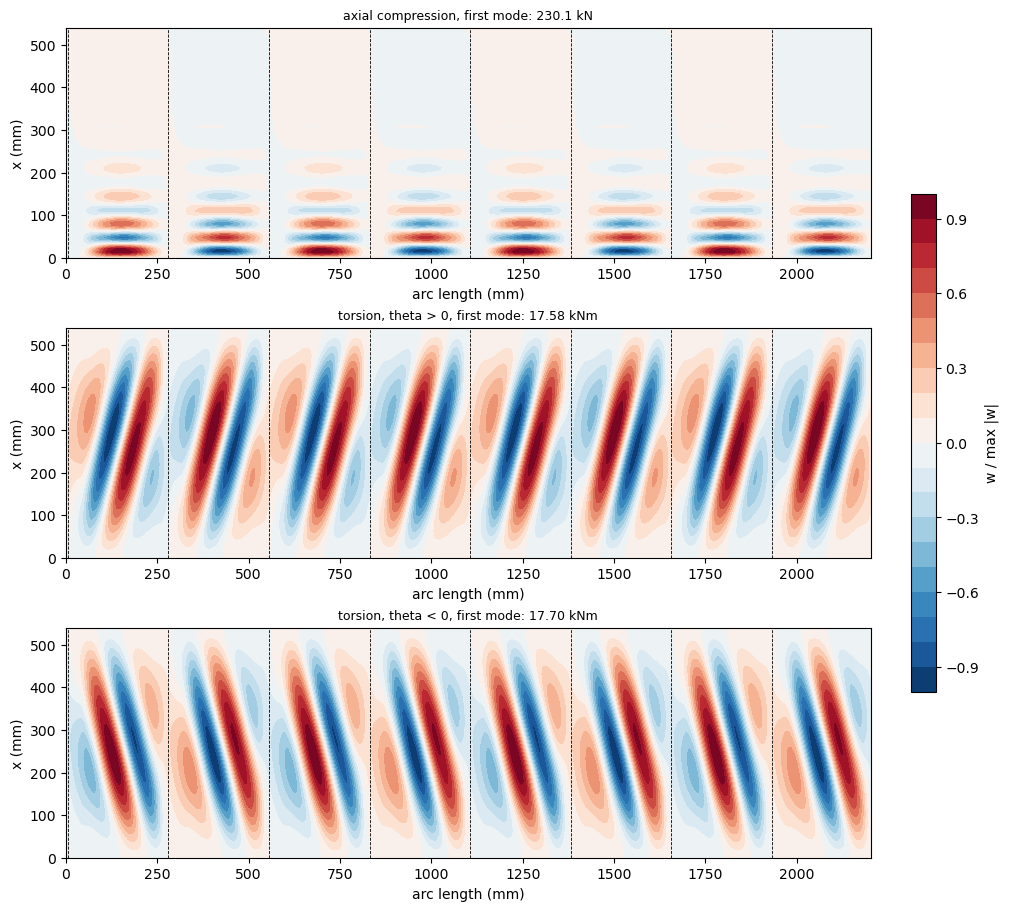

first eigenvalues, axial: [0.8844 0.8845 0.8845 0.8845]
first eigenvalues, torsion theta > 0: [1.6972 1.7069 1.7069 1.7316]


In [7]:
def plot_mode(ax_, res, title):
    X, S, W = pu.skin_field(res['parts']['skins'], res['evec'][:, 0], gridx=80)
    W = W/np.abs(W).max()
    cs = ax_.contourf(S, X, W, levels=np.linspace(-1, 1, 21), cmap='RdBu_r')
    for k in range(N_STRINGERS):
        ax_.axvline(k*pitch + REINF_LEFT, color='k', lw=0.6, ls='--')
    ax_.set_xlabel('arc length (mm)')
    ax_.set_ylabel('x (mm)')
    ax_.set_title(title, fontsize=9)
    return cs


fig, axes = plt.subplots(3, 1, figsize=(10, 9), constrained_layout=True)
plot_mode(axes[0], ax, 'axial compression, first mode: %.1f kN' % ax['crit'])
plot_mode(axes[1], to, 'torsion, theta > 0, first mode: %.2f kNm' % to['crit'])
cs = plot_mode(axes[2], to_neg, 'torsion, theta < 0, first mode: %.2f kNm'
               % abs(to_neg['crit']))
fig.colorbar(cs, ax=axes, shrink=0.6, label='w / max |w|')
plt.show()
print('first eigenvalues, axial:', np.round(ax['ev'], 4))
print('first eigenvalues, torsion theta > 0:', np.round(to['ev'], 4))

## 7. Sensitivity to the data that are not given

Each case changes one assumption of Section 1 or 2, with the mesh $m = 26$, $n = 26$ of Section 4:

* the lower end clamped ($w_{,x} = 0$), as the specimens clamped in the platforms of the test rig;
* the reinforcement [-45/0/45] of [3] instead of [45/-45/45] of [1];
* the skin plies listed from the outer face, i.e. [-45/0/45] from the inner face;
* the blade on the other edge of the foot (the L mirrored).

In [8]:
M_S, N_S = 26, 26
base = {load: conv[(load, M_S, N_S)]['crit'] for load in ('axial', 'torsion')}
cases = [('lower end clamped', dict(bottom='clamped')),
         ('reinforcement [-45/0/45] of [3]', dict(reinf_stack=[-45, 0, 45])),
         ('skin [-45/0/45] from the inner face', dict(skin_stack=[-45, 0, 45])),
         ('blade on the other edge of the foot',
          dict(blade_side='y2', reinf_left=(REINF_WIDTH - FOOT_OUT)/2))]
rows = [['model of Sections 2 to 5', '%.1f' % base['axial'], '', '%.2f' % base['torsion'], '']]
for name, kwargs in cases:
    res_a = solve('axial', M_S, N_S, **kwargs)
    res_t = solve('torsion', M_S, N_S, **kwargs)
    rows.append([name, '%.1f' % res_a['crit'], '%+.1f' % rel(res_a['crit'], base['axial']),
                 '%.2f' % res_t['crit'], '%+.1f' % rel(res_t['crit'], base['torsion'])])
print_table(rows, ['case (m = %d, n = %d)' % (M_S, N_S), 'axial (kN)', 'change %',
                   'torque, theta > 0 (kNm)', 'change %'])

              case (m = 26, n = 26)  axial (kN)  change %  torque, theta > 0 (kNm)  change %
-----------------------------------  ----------  --------  -----------------------  --------
           model of Sections 2 to 5       230.6                              17.58          
                  lower end clamped       242.9      +5.3                    17.65      +0.4
    reinforcement [-45/0/45] of [3]       241.4      +4.7                    17.65      +0.4
skin [-45/0/45] from the inner face       230.6      -0.0                    17.66      +0.5
blade on the other edge of the foot       230.5      -0.0                    17.61      +0.2


## 8. Discussion

**Convergence.** The first buckling load under axial compression needs many terms along the axis,
because the buckles are short and gather near the lower end (Section 6); it changes by 0.22 % from $m =
26$ to $m = 30$. The first buckling torque and both pre-buckling stiffnesses change by less than 0.01 %
over the whole study, and more terms across the strips, the feet and the blades change the loads by
0.007 % or less. The warnings printed during the study come from the null-space elimination of the
connections: the gap between the smallest independent pivot of the constraints (7.4e-7) and the largest
redundant one (1.5e-10) is narrower than usual but still of more than three orders of magnitude, and
the loads of all meshes follow the same convergence.

**Axial compression.** The first buckling load, 230.1 kN, is 8.0 % above the 213 kN of [1], Table 2.
The pre-buckling stiffness, 260.1 kN/mm, is 21 % above the 215 kN/mm of the same table, while it agrees
within 1.3 % with the membrane stiffness of the nominal cross-section, 256.8 kN/mm. The model of [1] is
therefore more flexible than the nominal data allow, by a cause that [1] does not give (e.g. the
modelling of the stringers, of the corner radius or of the clamped tabs), and the same cause probably
explains part of the difference of the buckling loads. The first mode has short buckles in all bays,
alternating from bay to bay, near the lower end, where the slope is free as in the finite element
model of [1]; the four first eigenvalues are equal within 0.01 %. With the lower end clamped, as the
specimens in the test rig, the load rises by 5.3 %.

**Torsion.** The first buckling torque, 17.58 kNm (17.70 kNm in the other sense), is 30 % above the
13.5 kNm of [1], Tables 3 and 4, and close to the 17.1 kNm that [1] gives for configuration B, with the
ring. None of the data examined in Section 7 changes it by more than 0.5 %. The first mode has one
inclined buckle across the height of each bay, all bays in phase, as the "ideal diagonal lines" from one
corner of each bay to the other that [1] describes for the post-buckling of configuration A (p. 75-10).

The pre-buckling torsional stiffness, 180.8 kNm/degree, is 8 % below the membrane estimate of the
closed section, which neglects the bending-extension coupling of the unsymmetric skin and of the
reinforcement on one side of it. The 15.8 kNm/degree of [1], Tables 3 and 4, is a tenth of these values
and of the measured pre-buckling stiffnesses of configuration B, 153 and 159 kNm/degree ([1], Table 5)
and 158 kNm/degree ([4], p. 148), which the central ring should hardly change; it is probably 158
kNm/degree misprinted. TODO(author): confirm the torsional stiffness of [1], Tables 3 and 4. Compared
with the tests, the model is 14 % to 18 % stiffer.

**Tests.** The tests were made on configuration B only. The first buckling torque measured is 15.3 and
15.0 kNm ([1], Table 5) and 15.2 kNm ([4], Table 4), between the first buckling torques computed by
[1] for configurations A and B. The ring is not modelled here, so these values are not compared with the
model of configuration A.

**What the comparison shows.** The plate assembly reproduces the stiffness of the nominal cross-section
and converges, and the unknown details of Section 1 change its buckling loads by 5.3 % at most. The
differences from [1] are larger, and come with a reference model that is more flexible than the nominal
section; without the details of that model they cannot be resolved here.

In [9]:
print('total run time: %.0f min' % ((time.time() - T_START)/60))

total run time: 77 min
